![Banner](../images/09_05_banner_rs_hyperspect.png)


# Target and Anomaly Detection

Detection asks a narrower question than classification: is a particular material present in this
pixel, even as a small fraction, against everything else in the scene? Hyperspectral detectors
model the background statistically and look for pixels that depart from it, either towards a known
target spectrum (target detection) or in any direction (anomaly detection). This notebook finds a
small eraser hidden in sugar with a target spectrum taken from a different laboratory scene, and
detects sub-pixel targets of known fraction implanted in a Tanager city scene, scoring every
detector with ROC curves.


## Overview

### Background and the Mahalanobis distance

Let **μ** and **Σ** be the mean and covariance of the background spectra. A pixel **x** is unusual
when it is far from **μ** in units of the background spread, measured by the Mahalanobis distance
`(x − μ)ᵀ Σ⁻¹ (x − μ)`. Whitening by **Σ⁻¹** is what makes hyperspectral detectors powerful: it
suppresses directions in which the background naturally varies (brightness, vegetation amount) and
amplifies directions in which it does not.

### Anomaly detection

- **RX** (Reed and Xiaoli 1990) is the Mahalanobis distance to the global background (global RX) or
  to a ring of pixels around each pixel, excluding a guard window (local RX). No target spectrum is
  needed, but every rare material is an anomaly, wanted or not.

### Target detection

With a target spectrum **t**:

- **Matched filter (MF)**: `(x − μ)ᵀ Σ⁻¹ (t − μ) / (t − μ)ᵀ Σ⁻¹ (t − μ)`, normalised so that a pure
  target scores about 1 and the background about 0; for small fractions the score approximates the
  target **abundance**.
- **Adaptive coherence estimator (ACE)** (Kraut and Scharf 1999): the squared cosine between the
  whitened pixel and the whitened target; between 0 and 1 and insensitive to pixel brightness.
- **Constrained energy minimisation (CEM)** (Harsanyi 1993): a filter with unit response to the
  target and minimum average output, using the correlation matrix (no mean removal).
- **Orthogonal subspace projection (OSP)** (Harsanyi and Chang 1994): projects out a set of known
  background signatures, then matches the target.

### Evaluating detectors

A detector produces a score map; a threshold turns it into detections. The **receiver operating
characteristic (ROC)** plots the true positive rate against the false alarm rate over all thresholds,
and its area (AUC) summarises it. In practice targets are rare, so what matters is the detection
rate at a very low false alarm rate (for example one in a thousand pixels).


## Detection with GeoLattice

`hs.rx` (global and local), `hs.matched_filter`, `hs.ace`, `hs.cem` and `hs.osp` return score maps on
the cube grid; a `background` mask restricts the statistics to chosen pixels and `shrinkage`
stabilises the covariance. `hs.detection_roc` computes the ROC table with the AUC in its attributes.

### Learning objectives

1. Compute global and local RX anomaly maps and interpret them.
2. Build a target spectrum from one scene and detect the target in another.
3. Compare MF, ACE, CEM and OSP and their sensitivity to background statistics.
4. Implant sub-pixel targets of known fraction and measure detection rates with ROC curves.
5. Use the matched filter score as an abundance estimate.

### Data

| Dataset | Use |
|---|---|
| HACARUS `rice` scene (three rice types and a small eraser) | Source of the eraser target spectrum |
| HACARUS `sugar_salt_flour_contamination` (an eraser hidden in sugar) | Detection test with an annotated target |
| Tanager urban scene (Portland), 300 by 300 pixel window | Background for implanted sub-pixel targets |
| Tanager energy and mining scene (Permian Basin) | Source of the implanted target: caliche (crushed carbonate) from a well pad |

The eraser positions come from the annotated previews shipped with the HACARUS data (`archive/img/`).

### Contents

- Setup
- Anomalies in a laboratory scene
- A target spectrum from another scene
- Four target detectors
- Implanting sub-pixel targets in a city
- ROC curves
- Matched filter scores as abundances
- Anomalies in the city
- Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import matplotlib.pyplot as plt  # figures

import geolattice  # GeoLattice
from geolattice.rsense import hyperspectral as hs  # hyperspectral cubes, readers and tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing/08_05_HyperSpectral")  # data folder next to this notebook
TANAGER = DATA / "Tanger"  # Planet Tanager sample scenes
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed


def tanager_file(category, product="sr"):
    """Path of a Tanager product (sr or radiance) for a scene category folder."""
    return next((TANAGER / category).glob(f"*/*_ortho_{product}_hdf5.h5"))


print("GeoLattice", geolattice.__version__)  # library version used for this notebook

import re  # wavelengths from file names
from PIL import Image  # PNG band images


def read_png_cube(folder):
    """Stack the *_<wavelength>nm.png band images of a HACARUS scene into a cube."""
    files = sorted(Path(folder).glob("*nm.png"), key=lambda p: float(re.search(r"_(\d+)nm", p.name)[1]))
    wl = [float(re.search(r"_(\d+)nm", p.name)[1]) for p in files]
    return hs.as_cube(np.stack([np.asarray(Image.open(p), dtype="float32") for p in files]), wl, name="dn")


def disc(shape, r, c, radius):
    """Boolean disc mask."""
    rr, cc = np.mgrid[:shape[0], :shape[1]]
    return (rr - r) ** 2 + (cc - c) ** 2 <= radius ** 2


def tpr_at(score, truth, far):
    """Share of target pixels above the threshold that only a fraction `far` of background pixels exceed."""
    s = np.asarray(getattr(score, "values", score), float)
    t = np.asarray(truth, bool)
    ok = np.isfinite(s)
    thr = np.quantile(s[ok & ~t], 1 - far)  # background quantile
    return float(np.mean(s[ok & t] > thr))

GeoLattice 0.3.43


## Anomalies in a laboratory scene


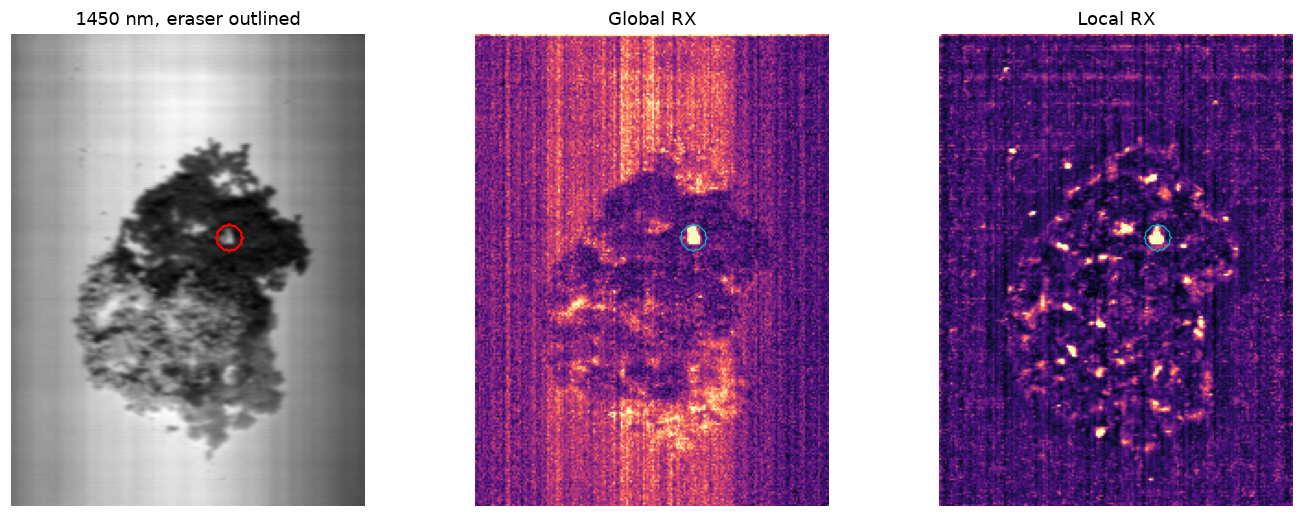

,AUC,TPR at FAR 1%
global RX,0.646,0.369
local RX,0.792,0.356


In [2]:
con = read_png_cube(DATA / "archive/data/sugar_salt_flour_contamination")  # powders and a hidden eraser
truth = disc(con.shape[1:], 110, 118, 7)  # eraser, from the annotated preview
rx_g = hs.rx(con)  # global RX on the first 10 principal components (default)
rx_l = hs.rx(con, mode="local", window=21, guard=7)  # local RX: ring between 7 and 10 pixels
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
axes[0].imshow(hs.band_at(con, 1450), cmap="gray"); axes[0].contour(truth, [0.5], colors="r")
axes[0].set_title("1450 nm, eraser outlined")
for ax, (t, m) in zip(axes[1:], [("Global RX", rx_g), ("Local RX", rx_l)]):
    ax.imshow(m, cmap="magma", vmax=np.nanpercentile(m, 99.5)); ax.contour(truth, [0.5], colors="c", linewidths=0.8); ax.set_title(t)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
rows = {t: {"AUC": hs.detection_roc(m, truth, n=2000).attrs["auc"], "TPR at FAR 1%": tpr_at(m, truth, 0.01)}
        for t, m in [("global RX", rx_g), ("local RX", rx_l)]}
pd.DataFrame(rows).T.round(3)

The eraser is the brightest spot in both RX maps, but it has competition. Global RX also lights up
the camera's vertical stripes (column to column differences of the push broom sensor, invisible in
the band image but rare in the statistics) and parts of the lower pile. Local RX suppresses the
stripes, because neighbouring columns share them, but turns every small irregularity in the powder
texture into speckle. Only about a third of the eraser disc is detected at a false alarm rate of 1
percent; part of the disc is mixed border pixels. Neither detector knows what the eraser looks like.


## A target spectrum from another scene

The rice scene, taken with the same camera, also contains a small eraser. Its spectrum, the mean of
a 3 by 3 window at the local RX peak near the annotated position, becomes the target signature for
the other scene. Using a signature from a different acquisition is the realistic case: a library or
field spectrum is never measured in the image being searched.


eraser found at (135, 155) in the rice scene


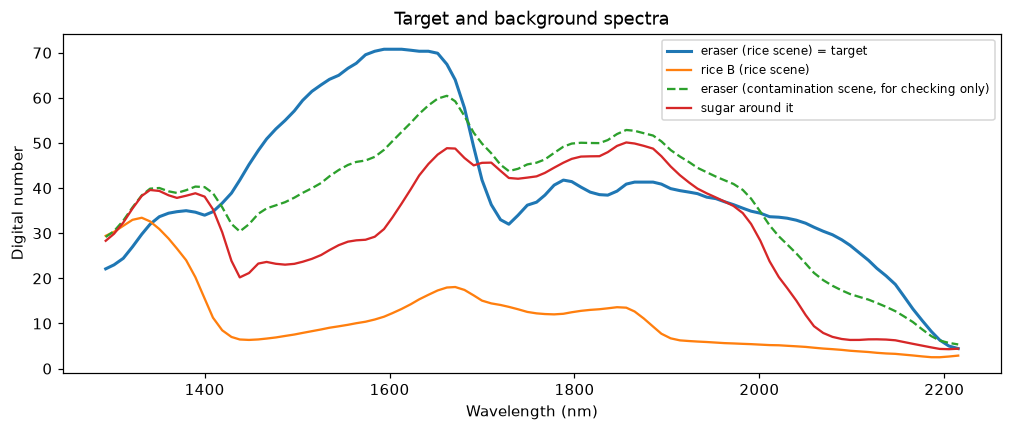

In [3]:
rice = read_png_cube(DATA / "archive/data/rice")
near = disc(rice.shape[1:], 135, 155, 12)  # around the annotated eraser
rxr = hs.rx(rice, mode="local", window=21, guard=7).values
r0, c0 = np.unravel_index(np.nanargmax(np.where(near, rxr, -np.inf)), rxr.shape)  # strongest anomaly there
target = rice.values[:, r0 - 1:r0 + 2, c0 - 1:c0 + 2].reshape(rice.sizes["band"], -1).mean(1)  # eraser spectrum
sugar_rice = rice.values[:, disc(rice.shape[1:], 110, 120, 20)].mean(1)  # rice B around it, for comparison
print("eraser found at", (int(r0), int(c0)), "in the rice scene")
wl = hs.wavelengths(con)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wl, target, lw=2, label="eraser (rice scene) = target")
ax.plot(wl, sugar_rice, label="rice B (rice scene)")
ax.plot(wl, con.values[:, truth].mean(1), "--", label="eraser (contamination scene, for checking only)")
ax.plot(wl, con.values[:, disc(con.shape[1:], 110, 118, 25) & ~disc(con.shape[1:], 110, 118, 12)].mean(1), label="sugar around it")
ax.set(xlabel="Wavelength (nm)", ylabel="Digital number", title="Target and background spectra"); ax.legend(fontsize=8)
plt.show()

The rice scene's eraser is bright between 1450 and 1900 nm and lacks the deep water and O-H
absorptions of rice and sugar near 1450 and 1940 nm. The eraser in the contamination scene (shown
only to check) is not identical: it is smaller, mixed with the sugar around it and lit differently,
so it shows part of the sugar's 1450 nm dip. The target therefore only approximates what the
detectors search for, as in any real application.


## Four target detectors

OSP needs signatures to suppress; the mean spectra of the tray and of the three powder piles are
used.


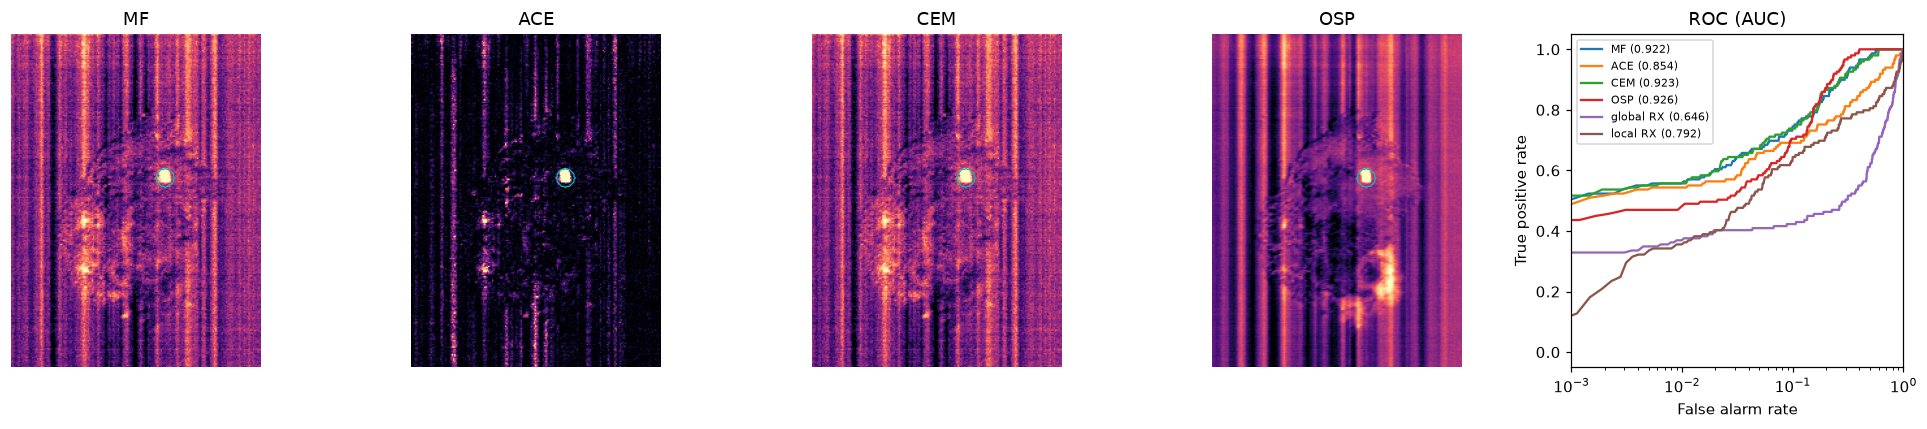

,AUC,TPR at FAR 0.1%,TPR at FAR 1%
MF,0.922,0.510,0.557
ACE,0.854,0.490,0.544
CEM,0.923,0.517,0.557
OSP,0.926,0.436,0.477
global RX,0.646,0.329,0.369
local RX,0.792,0.121,0.356


In [4]:
piles = {"tray": (30, 100), "sugar": (85, 100), "flour": (165, 55), "salt": (200, 115)}  # from the preview
undesired = np.array([con.values[:, disc(con.shape[1:], r, c, 8)].mean(1) for r, c in piles.values()])
scores = {"MF": hs.matched_filter(con, target), "ACE": hs.ace(con, target), "CEM": hs.cem(con, target),
          "OSP": hs.osp(con, target, undesired), "global RX": rx_g, "local RX": rx_l}
rocs = {k: hs.detection_roc(v, truth, n=2000) for k, v in scores.items()}
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, k in zip(axes, ["MF", "ACE", "CEM", "OSP"]):
    v = scores[k]
    ax.imshow(v, cmap="magma", vmin=np.nanpercentile(v, 1), vmax=np.nanpercentile(v, 99.8)); ax.set_title(k)
    ax.contour(truth, [0.5], colors="c", linewidths=0.8); ax.axis("off")
for k, roc in rocs.items():
    axes[4].plot(roc["far"], roc["tpr"], label=f"{k} ({roc.attrs['auc']:.3f})")
axes[4].set(xscale="log", xlim=(1e-3, 1), xlabel="False alarm rate", ylabel="True positive rate", title="ROC (AUC)")
axes[4].legend(fontsize=7)
plt.tight_layout()
plt.show()
pd.DataFrame({k: {"AUC": r.attrs["auc"], "TPR at FAR 0.1%": tpr_at(scores[k], truth, 0.001),
                  "TPR at FAR 1%": tpr_at(scores[k], truth, 0.01)} for k, r in rocs.items()}).T.round(3)

With a target signature the detectors beat RX: about half of the eraser disc is found at a false
alarm rate of 0.1 percent with MF, CEM and ACE, against a third or less with RX. The score maps
also show what limits them: whitening amplifies the camera's vertical stripes, which are rare in the
statistics, so stripes become the main source of false alarms (most visibly in OSP, which suppresses
only the four signatures it is given). The truth disc includes mixed border pixels, so no detector
reaches a true positive rate of 1. Destriping the cube first (notebook 09_05_02) is the obvious next
step.


## Implanting sub-pixel targets in a city

To measure detection at known fractions, 40 pixels of the Portland window are replaced by linear
mixtures of the original pixel and a target: crushed caliche (calcium carbonate) taken from a well
pad in the Permian Basin scene, a material absent from the city. The fractions are spread evenly
between 2 and 40 percent.


target pixel from the Permian Basin: (210, 21) | 2340 nm depth 0.175


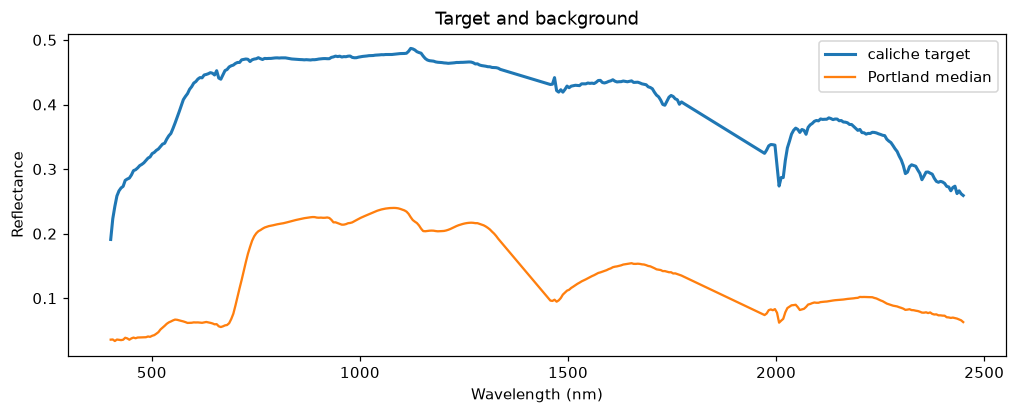

In [5]:
urban = hs.drop_bad_bands(hs.read_tanager(tanager_file("urban"), window=(slice(319, 619), slice(285, 585))))
em = hs.read_tanager(tanager_file("energy-mining"), window=(slice(400, 650), slice(350, 600)))
em = em.sel(band=urban["band"])  # same good bands as the urban cube
cd = hs.band_depth(em, 2340, 2270, 2400)["depth"].values  # carbonate feature depth
r, c = np.unravel_index(np.nanargmax(cd), cd.shape)  # deepest carbonate pixel: a caliche pad
caliche = em.values[:, r - 1:r + 2, c - 1:c + 2].reshape(em.sizes["band"], -1).mean(1)  # 3 x 3 mean spectrum

rng = np.random.default_rng(1)
H, W = urban.shape[1:]
flat = rng.choice(H * W, 40, replace=False)  # 40 random pixels
rows_, cols_ = np.unravel_index(flat, (H, W))
frac = np.linspace(0.02, 0.40, 40)  # known target fractions
implanted = urban.copy()
X = implanted.values
for rr, cc, f in zip(rows_, cols_, frac):
    X[:, rr, cc] = (1 - f) * X[:, rr, cc] + f * caliche  # linear mixture
truth_u = np.zeros((H, W), bool); truth_u[rows_, cols_] = True
print("target pixel from the Permian Basin:", (int(r), int(c)), f"| 2340 nm depth {cd[r, c]:.3f}")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(hs.wavelengths(urban), caliche, lw=2, label="caliche target")
ax.plot(hs.wavelengths(urban), np.nanmedian(urban.values.reshape(urban.sizes["band"], -1), 1), label="Portland median")
ax.set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Target and background"); ax.legend()
plt.show()

## ROC curves

The background statistics are estimated from all pixels, including the 40 targets, as they would be
in a real search. Every detector gets the caliche spectrum; OSP suppresses five N-FINDR endmembers of
the original window.


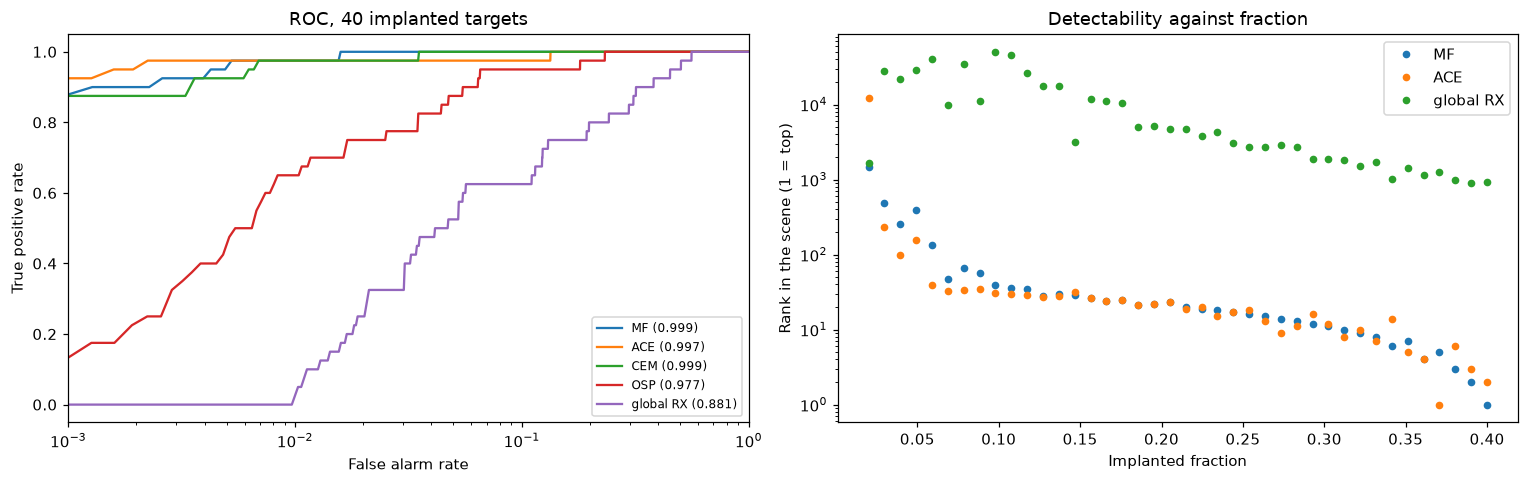

,AUC,TPR at FAR 0.01%,TPR at FAR 0.1%
MF,0.999,0.800,0.875
ACE,0.997,0.900,0.925
CEM,0.999,0.775,0.875
OSP,0.977,0.000,0.125
global RX,0.881,0.000,0.000


In [6]:
undes_u = hs.nfindr(urban, 5)["spectra"]  # background signatures for OSP
det = {"MF": hs.matched_filter(implanted, caliche), "ACE": hs.ace(implanted, caliche),
       "CEM": hs.cem(implanted, caliche), "OSP": hs.osp(implanted, caliche, undes_u),
       "global RX": hs.rx(implanted, n_components=20)}
roc_u = {k: hs.detection_roc(v, truth_u, n=3000) for k, v in det.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k, roc in roc_u.items():
    axes[0].plot(roc["far"], roc["tpr"], label=f"{k} ({roc.attrs['auc']:.3f})")
axes[0].set(xscale="log", xlim=(1e-3, 1), xlabel="False alarm rate", ylabel="True positive rate", title="ROC, 40 implanted targets")
axes[0].legend(fontsize=8)
for k in ["MF", "ACE", "global RX"]:
    v = det[k].values
    tv = v[rows_, cols_]  # target scores, in the order of frac
    rank = (tv[:, None] < np.nan_to_num(v, nan=-np.inf).ravel()[None, :]).sum(1)  # pixels scoring higher
    axes[1].semilogy(frac, rank + 1, "o", ms=4, label=k)
axes[1].set(xlabel="Implanted fraction", ylabel="Rank in the scene (1 = top)", title="Detectability against fraction")
axes[1].legend()
plt.tight_layout()
plt.show()
pd.DataFrame({k: {"AUC": r.attrs["auc"], "TPR at FAR 0.01%": tpr_at(det[k], truth_u, 1e-4),
                  "TPR at FAR 0.1%": tpr_at(det[k], truth_u, 1e-3)} for k, r in roc_u.items()}).T.round(3)

MF, ACE and CEM find 78 to 90 percent of the implanted pixels at a false alarm rate of one in ten
thousand (nine false pixels in the window), and ACE is the best at the lowest rates. The rank plot
shows the limit: the rank falls steadily with the fraction, every target above about 6 percent is
among the top 40 MF and ACE scores of the 90,000 pixels, and below that the targets sink into the
background, ranking in the hundreds to thousands. RX ranks the targets in the thousands, because the city has many other rare spectra, and
OSP fails at low false alarm rates: five endmembers are far too few to describe the urban background.


## Matched filter scores as abundances


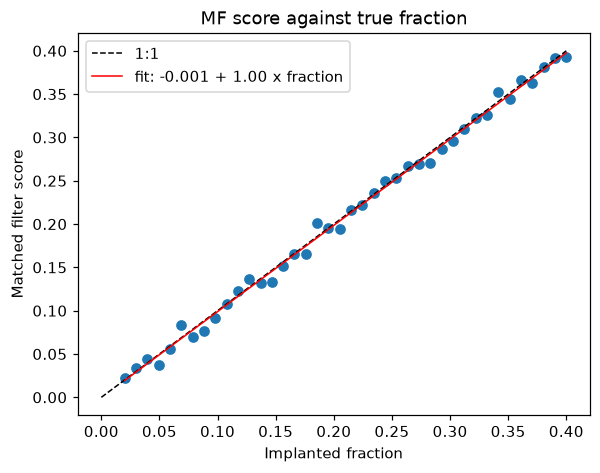

correlation 0.998 | background MF: median -0.000, 99.9th percentile 0.057


In [7]:
mf_by_frac = det["MF"].values[rows_, cols_]  # MF score of each target, in the order of frac
slope, icpt = np.polyfit(frac, mf_by_frac, 1)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(frac, mf_by_frac, "o")
ax.plot([0, 0.4], [0, 0.4], "k--", lw=1, label="1:1")
ax.plot(frac, icpt + slope * frac, "r-", lw=1, label=f"fit: {icpt:.3f} + {slope:.2f} x fraction")
ax.set(xlabel="Implanted fraction", ylabel="Matched filter score", title="MF score against true fraction"); ax.legend()
plt.show()
print(f"correlation {np.corrcoef(frac, mf_by_frac)[0, 1]:.3f} | background MF: median {np.nanmedian(det['MF'].values[~truth_u]):.3f}, "
      f"99.9th percentile {np.nanpercentile(det['MF'].values[~truth_u], 99.9):.3f}")

The matched filter score rises linearly with the implanted fraction, so after normalisation it is an
abundance estimate, the basis of gas plume retrieval in the next notebook (where the "target" is a
methane absorption spectrum and the score becomes a column enhancement). The fit has a slope of
1.00 and no offset. Scatter around the line comes from the background pixel each target was mixed
into; the 99.9th percentile of the background score (about 0.06) is the fraction above which a
target stands out from all but one in a thousand background pixels.


## Anomalies in the city

Without implanted targets, what does RX find in Portland?


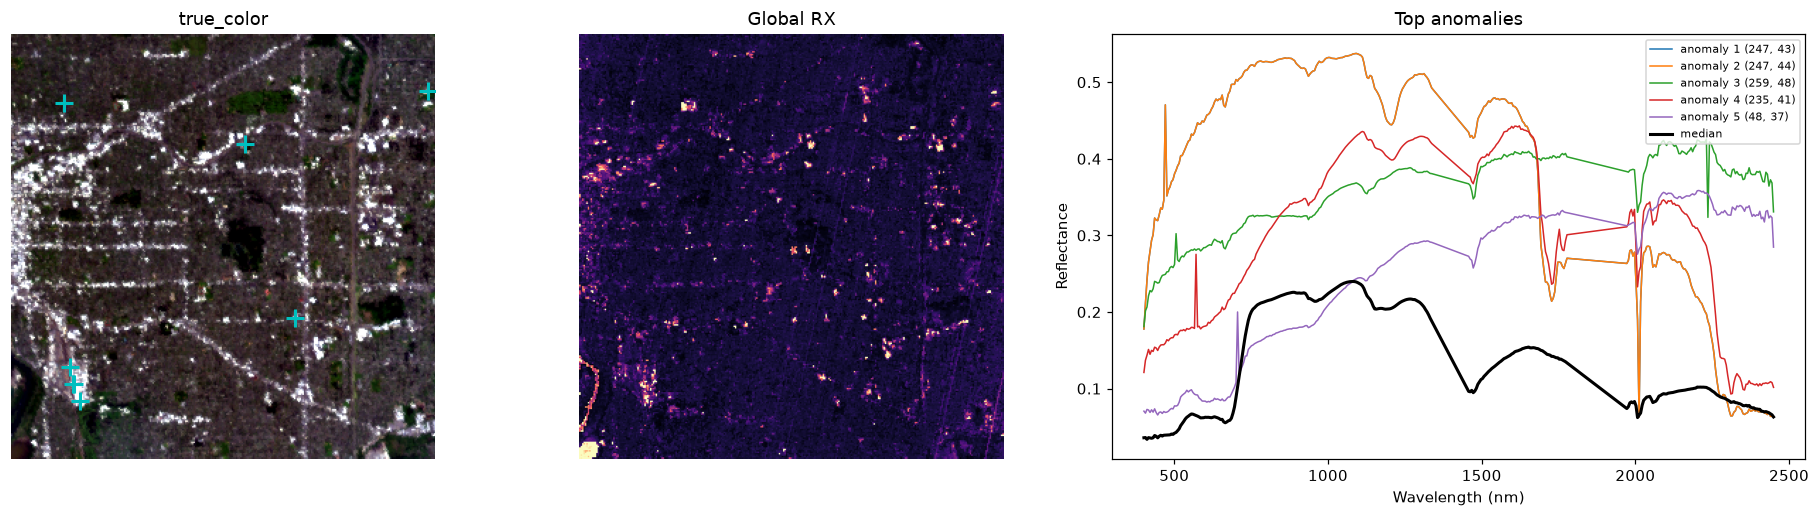

In [8]:
rx_u = hs.rx(urban, n_components=20)  # global RX on the original window
top = np.argsort(np.nan_to_num(rx_u.values, nan=-1).ravel())[-8:][::-1]  # eight most anomalous pixels
tr, tc = np.unravel_index(top, rx_u.shape)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.4]})
hs.plot_rgb(urban, "true_color", ax=axes[0]); axes[0].plot(tc, tr, "c+", ms=12, mew=2)
axes[1].imshow(rx_u, cmap="magma", vmax=np.nanpercentile(rx_u, 99.5)); axes[1].set_title("Global RX"); axes[1].axis("off")
for i, (a, b) in enumerate(zip(tr[:5], tc[:5])):
    axes[2].plot(hs.wavelengths(urban), urban.values[:, a, b], lw=1, label=f"anomaly {i + 1} ({a}, {b})")
axes[2].plot(hs.wavelengths(urban), np.nanmedian(urban.values.reshape(urban.sizes["band"], -1), 1), "k", lw=2, label="median")
axes[2].set(xlabel="Wavelength (nm)", ylabel="Reflectance", title="Top anomalies"); axes[2].legend(fontsize=7)
plt.tight_layout()
plt.show()

The strongest anomalies are a few unusual surfaces: very bright roofs and spectra with unusual SWIR
features (roofing materials or coatings) that occur in only a handful of pixels. RX finds them
without any prior knowledge, which makes it a good screening tool, but every one of them has to be
inspected; a target detector with the right signature is far more selective.


## Summary and exercises

**Key points**

- Whitening by the background covariance is what makes hyperspectral detectors sensitive to small
  targets.
- RX needs no signature but flags every rare material; local RX favours small objects in uniform
  surroundings.
- With a target signature, even one from another acquisition, MF, ACE and CEM detect targets far more
  selectively than RX; OSP depends on how well its undesired signatures describe the background.
- Implanted targets of known fraction give honest ROC curves: detection is reliable above a few
  percent fraction in a city at 30 m, and the matched filter score estimates the fraction.

**`geolattice.rsense.hyperspectral` functions used:** `rx`, `matched_filter`, `ace`, `cem`, `osp`,
`detection_roc`, `nfindr`, `band_depth`, `band_at`, `read_tanager`, `drop_bad_bands`, `as_cube`,
`plot_rgb`.

**Exercises**

1. Estimate the background for the matched filter only from pixels outside the piles
   (`background=` mask). Does detection of the eraser improve?
2. Implant the targets at fractions between 0.5 and 5 percent. At what fraction does the MF detection
   rate at a false alarm rate of 0.1 percent fall below one half?
3. Add `shrinkage=1e-3` to the matched filter in the city. Why can shrinkage help when the number of
   pixels is small compared with the number of bands?
4. Use the snow spectrum from notebook 09_05_00 as the target in the city. What do the strongest
   detections look like?
